# Chapter 2 — Pre-Model Workflow and Data Preprocessing

**Sumber:** *scikit-learn Cookbook*, 3rd Ed. (John Sukup, Packt, 2025)

Kualitas sebuah model *machine learning* sangat ditentukan oleh kualitas data yang masuk ke dalamnya — prinsip *"garbage in, garbage out"*. Chapter 2 membahas tahap **sebelum pemodelan** (*pre-model workflow*): bagaimana menangani nilai yang hilang, menyamakan skala fitur, mengubah data kategorikal menjadi angka, merangkai semua langkah itu dalam sebuah `Pipeline`, serta membuat dan memilih fitur (*feature engineering & selection*). Semua langkah ini menggunakan API *transformer* scikit-learn yang seragam: `fit()` → `transform()` (atau `fit_transform()`).

**Daftar Isi**

| No | Recipe | Kelas scikit-learn utama |
|---|---|---|
| 2.1 | Penanganan Missing Data | `SimpleImputer`, `KNNImputer`, `IterativeImputer` |
| 2.2 | Teknik Scaling | `StandardScaler`, `MinMaxScaler`, `Normalizer` |
| 2.3 | Encoding Variabel Kategorikal | `OneHotEncoder`, `LabelEncoder`, `ColumnTransformer` |
| 2.4 | Pengantar Pipeline (+ visualisasi pipeline) | `Pipeline`, `set_config` |
| 2.5 | Feature Engineering & Feature Selection | `PolynomialFeatures`, `KBinsDiscretizer`, `RFE`, `SelectFromModel` |
| Latihan | Pipeline komprehensif pada California Housing | `Pipeline`, `RandomForestRegressor` |

> **Catatan:** Notebook ini mereproduksi seluruh kode dari chapter (berdasarkan notebook resmi Packt, urutan recipe dipertahankan) dan menambahkan penjelasan teori, rumus, serta interpretasi output dalam Bahasa Indonesia. Kode dijalankan dengan scikit-learn 1.9.x (buku ditulis untuk 1.5); penyesuaian kecil dicatat di bagian yang relevan.

## Import Library

Library inti yang dipakai di seluruh notebook. Import spesifik untuk tiap recipe tetap ditulis ulang di sel masing-masing (mengikuti gaya buku) agar setiap recipe bisa dibaca secara mandiri.

In [1]:
%matplotlib inline
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

# Tampilan pandas agar tabel lebih ringkas
pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="whitegrid")

print("numpy       :", np.__version__)
print("pandas      :", pd.__version__)
print("scikit-learn:", sklearn.__version__)

numpy       : 2.5.3
pandas      : 3.0.6
scikit-learn: 1.9.1


## 2.1 Penanganan Missing Data

**Teori:**

*Missing data* (nilai hilang, `NaN`) sangat umum di data nyata: sensor rusak, responden tidak mengisi survei, kesalahan input, dll. Sebagian besar estimator scikit-learn (misalnya `LinearRegression`, `SVC`) **tidak bisa menerima `NaN`**, sehingga kita harus menghapus atau **mengimputasi** (mengisi) nilai tersebut.

**Mekanisme missing data (Rubin, 1976)** — menentukan strategi mana yang aman:

| Mekanisme | Arti | Contoh | Implikasi |
|---|---|---|---|
| **MCAR** (*Missing Completely At Random*) | Peluang hilang tidak bergantung pada data apa pun | Data hilang karena file korup secara acak | Imputasi sederhana / penghapusan relatif tidak bias |
| **MAR** (*Missing At Random*) | Peluang hilang bergantung pada fitur lain yang **teramati** | Pendapatan sering kosong pada responden muda | Imputasi multivariat (KNN, iterative) lebih tepat |
| **MNAR** (*Missing Not At Random*) | Peluang hilang bergantung pada **nilai yang hilang itu sendiri** | Orang berpenghasilan sangat tinggi enggan menyebut gaji | Sulit; perlu pemodelan domain / indikator missing |

Dataset pada recipe ini dibuat dengan pola MCAR (nilai dihapus acak ~20%).

**Tiga imputer di scikit-learn:**

1. **`SimpleImputer`** (univariat) — setiap kolom diisi dengan satu statistik kolom itu sendiri:
   - `mean`: $\hat{x}_{ij} = \bar{x}_j = \frac{1}{|O_j|}\sum_{i \in O_j} x_{ij}$, dengan $O_j$ = indeks baris yang teramati pada kolom $j$.
   - `median`: lebih *robust* terhadap outlier.
   - `most_frequent` (modus): cocok untuk data kategorikal.
   - `constant`: diisi nilai tetap (`fill_value`).

   Kelemahannya: varians fitur menyusut (banyak nilai identik di pusat distribusi) dan korelasi antar-fitur diabaikan.

2. **`KNNImputer`** (multivariat, berbasis jarak) — untuk baris dengan nilai hilang, cari $k$ tetangga terdekat yang memiliki nilai pada kolom tersebut, lalu ambil rata-ratanya:
   $$\hat{x}_{ij} = \frac{1}{k}\sum_{l \in N_k(i)} x_{lj}$$
   Jarak dihitung dengan **`nan_euclidean`**, yaitu jarak Euclidean yang hanya memakai koordinat yang teramati pada kedua baris lalu diskalakan ulang:
   $$d(\mathbf{a},\mathbf{b}) = \sqrt{\frac{p}{|P|}\sum_{m \in P}(a_m - b_m)^2}$$
   dengan $p$ = jumlah total fitur dan $P$ = himpunan fitur yang teramati pada kedua vektor. Karena berbasis jarak, KNNImputer sensitif terhadap skala fitur.

3. **`IterativeImputer`** (multivariat, berbasis model; terinspirasi **MICE** — *Multivariate Imputation by Chained Equations*) — setiap fitur yang memiliki nilai hilang dimodelkan sebagai fungsi fitur lain:
   $$x_j \approx f_j(\mathbf{x}_{-j}), \quad j = 1,\dots,p$$
   Algoritmanya: (a) isi awal dengan mean; (b) untuk setiap fitur $j$ secara bergiliran, latih regresor (default `BayesianRidge`) pada baris yang teramati, lalu prediksi nilai yang hilang; (c) ulangi beberapa putaran (`max_iter`, default 10) sampai perubahan kecil (`tol`). Kelas ini masih berstatus **eksperimental**, sehingga perlu `from sklearn.experimental import enable_iterative_imputer`.

**Prinsip penting:** imputer harus di-`fit` **hanya pada data latih**, lalu dipakai untuk `transform` data uji — kalau tidak, informasi data uji "bocor" (*data leakage*).

### Getting ready — membuat dataset dengan missing values
Dataset sintetis: 20 baris × 10 fitur, nilai seragam $U(0, 100)$, lalu sekitar 20% sel tiap kolom diganti `NaN`.

In [2]:
# Load libraries
import numpy as np
import pandas as pd

# Membuat dataset sampel dengan missing values
np.random.seed(2024)  # Untuk reproducibility
n_samples = 20
n_features = 10

# Membangkitkan data acak uniform pada rentang [0, 100)
data = {
    f"Feature{i+1}": np.random.uniform(0, 100, n_samples) for i in range(n_features)
}

# Konversi ke DataFrame
df = pd.DataFrame(data)

# Menyisipkan missing values secara acak (sekitar 20% dari data)
for column in df.columns:
    mask = np.random.random(n_samples) < 0.2
    df.loc[mask, column] = np.nan

# Menampilkan DataFrame dengan missing values
display(df)

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,58.801,NaN,42.010,34.680,49.962,NaN,NaN,89.955,41.152,NaN
1,69.911,9.554,6.436,31.288,37.966,NaN,82.006,NaN,75.798,91.382
2,NaN,96.091,59.643,84.710,NaN,84.109,NaN,70.288,1.778,4.118
3,NaN,25.177,83.732,88.023,16.887,97.206,84.697,NaN,NaN,80.078
4,20.502,NaN,89.249,67.656,58.636,78.226,60.912,NaN,65.114,99.119
5,10.606,76.825,20.053,5.368,NaN,19.703,34.423,93.399,72.207,12.640
6,72.724,79.792,50.240,55.921,6.191,NaN,22.967,21.049,57.359,14.303
7,NaN,NaN,89.538,69.451,NaN,47.886,NaN,33.620,99.686,6.683
8,47.385,NaN,25.592,82.420,73.415,61.664,29.173,65.947,61.005,34.053
9,44.830,38.165,NaN,31.143,28.866,NaN,41.004,41.460,50.236,NaN


In [3]:
# Tambahan: ringkasan jumlah missing value per kolom
missing_summary = pd.DataFrame({
    "jumlah_NaN": df.isna().sum(),
    "persen_NaN": (df.isna().mean() * 100).round(1),
})
print("Total sel NaN:", int(df.isna().sum().sum()), "dari", df.size, "sel")
missing_summary.T

Total sel NaN: 44 dari 200 sel


,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
jumlah_NaN,3.0,5.0,4.0,4.0,5.0,5.0,7.0,6.0,2.0,3.0
persen_NaN,15.0,25.0,20.0,20.0,25.0,25.0,35.0,30.0,10.0,15.0


**Interpretasi:** Setiap kolom memiliki beberapa sel `NaN` dengan proporsi yang bervariasi di sekitar 20% (karena dihasilkan secara acak per sel, ada kolom yang lebih banyak atau lebih sedikit dari 20%). Data seperti ini tidak bisa langsung dimasukkan ke sebagian besar estimator scikit-learn, sehingga perlu imputasi.

### How to do it — `SimpleImputer`
Strategi `mean`: setiap `NaN` diganti dengan rata-rata kolomnya (dihitung dari nilai yang teramati saja).

In [4]:
# Load libraries
from sklearn.impute import SimpleImputer

# Inisialisasi SimpleImputer; strategy bisa "mean", "median", "most_frequent", atau "constant"
imputer = SimpleImputer(strategy="mean")

# Fit (hitung mean tiap kolom) lalu transform (isi NaN)
imputed_data = imputer.fit_transform(df)
imputed_df = pd.DataFrame(imputed_data, columns=df.columns)
imputed_df

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,58.801,53.865,42.010,34.680,49.962,57.823,51.145,89.955,41.152,48.400
1,69.911,9.554,6.436,31.288,37.966,57.823,82.006,50.715,75.798,91.382
2,52.559,96.091,59.643,84.710,46.056,84.109,51.145,70.288,1.778,4.118
3,52.559,25.177,83.732,88.023,16.887,97.206,84.697,50.715,60.617,80.078
4,20.502,53.865,89.249,67.656,58.636,78.226,60.912,50.715,65.114,99.119
5,10.606,76.825,20.053,5.368,46.056,19.703,34.423,93.399,72.207,12.640
6,72.724,79.792,50.240,55.921,6.191,57.823,22.967,21.049,57.359,14.303
7,52.559,53.865,89.538,69.451,46.056,47.886,51.145,33.620,99.686,6.683
8,47.385,53.865,25.592,82.420,73.415,61.664,29.173,65.947,61.005,34.053
9,44.830,38.165,52.898,31.143,28.866,57.823,41.004,41.460,50.236,48.400


In [5]:
# Tambahan: nilai pengisi yang dipelajari imputer (statistics_) = mean tiap kolom
pd.DataFrame({"mean_teramati": df.mean(), "statistics_": imputer.statistics_}).T

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
mean_teramati,52.559,53.865,52.898,54.962,46.056,57.823,51.145,50.715,60.617,48.4
statistics_,52.559,53.865,52.898,54.962,46.056,57.823,51.145,50.715,60.617,48.4


**Interpretasi:** Semua `NaN` kini terisi. Atribut `statistics_` identik dengan `df.mean()` (pandas otomatis mengabaikan `NaN`), membuktikan bahwa setiap sel yang hilang diisi dengan **satu nilai yang sama per kolom**. Akibatnya, baris-baris yang tadinya hilang menjadi identik pada kolom tersebut — distribusi menjadi "menumpuk" di rata-rata dan varians kolom mengecil.

### How to do it — `KNNImputer`
Setiap `NaN` diisi dengan rata-rata nilai kolom tersebut dari $k=2$ baris terdekat (jarak `nan_euclidean`).

In [6]:
# Load libraries
from sklearn.impute import KNNImputer

# Inisialisasi KNNImputer dengan 2 tetangga terdekat
knn_imputer = KNNImputer(n_neighbors=2)

# Fit dan transform DataFrame yang sama
knn_imputed_data = knn_imputer.fit_transform(df)
knn_imputed_df = pd.DataFrame(knn_imputed_data, columns=df.columns)
knn_imputed_df

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,58.801,48.954,42.010,34.680,49.962,93.910,52.549,89.955,41.152,59.834
1,69.911,9.554,6.436,31.288,37.966,86.793,82.006,45.416,75.798,91.382
2,67.752,96.091,59.643,84.710,73.338,84.109,59.013,70.288,1.778,4.118
3,47.881,25.177,83.732,88.023,16.887,97.206,84.697,64.510,39.727,80.078
4,20.502,31.671,89.249,67.656,58.636,78.226,60.912,25.904,65.114,99.119
5,10.606,76.825,20.053,5.368,59.717,19.703,34.423,93.399,72.207,12.640
6,72.724,79.792,50.240,55.921,6.191,40.483,22.967,21.049,57.359,14.303
7,47.630,77.844,89.538,69.451,32.753,47.886,55.683,33.620,99.686,6.683
8,47.385,35.181,25.592,82.420,73.415,61.664,29.173,65.947,61.005,34.053
9,44.830,38.165,29.188,31.143,28.866,59.675,41.004,41.460,50.236,35.001


**Interpretasi:** Berbeda dengan `SimpleImputer`, nilai yang diisi kini **berbeda-beda per baris**, karena bergantung pada tetangga terdekat masing-masing baris. Dengan $k=2$, setiap nilai imputasi adalah rata-rata dua angka, sehingga hasilnya lebih "lokal" tetapi juga lebih bervariasi (rentan noise). Pada data uniform acak seperti ini, korelasi antar-fitur hampir nol, sehingga "kedekatan" antar-baris tidak terlalu informatif — keunggulan KNN akan lebih terasa di data nyata yang fitur-fiturnya saling berkorelasi.

### How to do it — `IterativeImputer`
Setiap fitur yang hilang diprediksi dari fitur-fitur lain dengan regresi `BayesianRidge`, diulang secara bergiliran (gaya MICE).

In [7]:
# Load libraries
from sklearn.experimental import enable_iterative_imputer  # Fitur eksperimental, wajib di-import dulu
from sklearn.impute import IterativeImputer

# Inisialisasi IterativeImputer (random_state ditambahkan untuk reproducibility)
iterative_imputer = IterativeImputer(random_state=2024)

# Fit dan transform DataFrame yang sama
iterative_imputed_data = iterative_imputer.fit_transform(df)
iterative_imputed_df = pd.DataFrame(iterative_imputed_data, columns=df.columns)
iterative_imputed_df

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,58.801,54.365,42.010,34.680,49.962,58.681,51.178,89.955,41.152,48.292
1,69.911,9.554,6.436,31.288,37.966,60.071,82.006,50.710,75.798,91.382
2,52.540,96.091,59.643,84.710,46.121,84.109,51.155,70.288,1.778,4.118
3,52.631,25.177,83.732,88.023,16.887,97.206,84.697,50.680,50.651,80.078
4,20.502,53.199,89.249,67.656,58.636,78.226,60.912,50.692,65.114,99.119
5,10.606,76.825,20.053,5.368,46.156,19.703,34.423,93.399,72.207,12.640
6,72.724,79.792,50.240,55.921,6.191,55.924,22.967,21.049,57.359,14.303
7,52.558,53.943,89.538,69.451,46.070,47.886,50.970,33.620,99.686,6.683
8,47.385,54.205,25.592,82.420,73.415,61.664,29.173,65.947,61.005,34.053
9,44.830,38.165,52.883,31.143,28.866,55.978,41.004,41.460,50.236,48.430


Jumlah iterasi IterativeImputer: 3


,Simple (mean),KNN (k=2),Iterative
mean,52.422,54.383,52.191
std,3.727,18.124,3.535
min,46.056,23.094,45.970
max,60.617,93.910,60.071


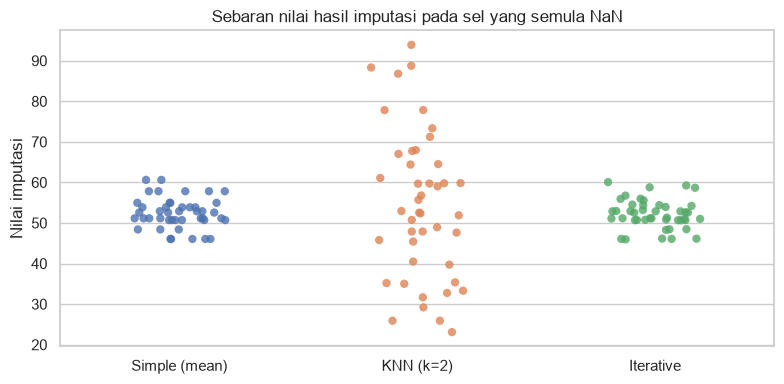

In [8]:
# Tambahan: membandingkan nilai imputasi ketiga metode pada sel-sel yang semula NaN
mask_nan = df.isna()
perbandingan = pd.DataFrame({
    "Simple (mean)": imputed_df.values[mask_nan.values],
    "KNN (k=2)": knn_imputed_df.values[mask_nan.values],
    "Iterative": iterative_imputed_df.values[mask_nan.values],
})
print("Jumlah iterasi IterativeImputer:", iterative_imputer.n_iter_)
display(perbandingan.describe().loc[["mean", "std", "min", "max"]])

fig, ax = plt.subplots(figsize=(8, 4))
sns.stripplot(data=perbandingan, ax=ax, jitter=0.2, size=6, alpha=0.8)
ax.set_title("Sebaran nilai hasil imputasi pada sel yang semula NaN")
ax.set_ylabel("Nilai imputasi")
plt.tight_layout()
plt.show()

**Interpretasi:** `IterativeImputer` mengisi tiap sel dengan prediksi regresi, sehingga nilainya juga berbeda-beda per baris. Grafik memperlihatkan perbedaan karakter ketiga metode: imputasi *mean* hanya menghasilkan satu nilai per kolom (sebaran sempit), KNN menghasilkan sebaran paling lebar (rata-rata dua tetangga saja), sedangkan Iterative cenderung berada dekat rata-rata karena — pada data acak tanpa korelasi — `BayesianRidge` menyusutkan koefisien ke nol sehingga prediksinya mendekati mean. Pada data nyata dengan korelasi kuat antar-fitur, metode multivariat (KNN/Iterative) biasanya lebih akurat daripada imputasi mean.

## 2.2 Teknik Scaling

**Teori:**

Fitur sering memiliki satuan dan rentang yang sangat berbeda (misalnya umur 20–60 vs gaji 3.000.000–50.000.000). Algoritma berbasis **jarak** (k-NN, k-Means, SVM dengan kernel RBF), berbasis **gradien** (regresi logistik, neural network), dan yang memakai **regularisasi** (Ridge, Lasso) atau **PCA** sangat terpengaruh skala: fitur dengan rentang besar akan mendominasi. Sebaliknya, model berbasis pohon (Decision Tree, Random Forest) praktis invarian terhadap transformasi monoton per fitur.

| Transformer | Arah operasi | Rumus | Hasil | Catatan |
|---|---|---|---|---|
| `StandardScaler` | per **kolom** (fitur) | $z_{ij} = \dfrac{x_{ij} - \mu_j}{\sigma_j}$ | mean 0, std 1 | Sensitif outlier (mean & std terpengaruh); cocok untuk data ~ normal |
| `MinMaxScaler` | per **kolom** | $x'_{ij} = \dfrac{x_{ij} - \min_j}{\max_j - \min_j}$ | rentang $[0,1]$ (atau `feature_range`) | Sangat sensitif outlier; mempertahankan bentuk distribusi |
| `Normalizer` | per **baris** (sampel) | $\mathbf{x}'_i = \dfrac{\mathbf{x}_i}{\lVert\mathbf{x}_i\rVert_2}$ | setiap baris memiliki norma 1 | Berguna untuk *cosine similarity*, teks (TF-IDF) |

Detail:
- Pada `StandardScaler`, $\mu_j = \frac{1}{n}\sum_i x_{ij}$ dan $\sigma_j = \sqrt{\frac{1}{n}\sum_i (x_{ij}-\mu_j)^2}$ (scikit-learn memakai simpangan baku **populasi**, `ddof=0`).
- Pada `Normalizer`, norma default adalah L2: $\lVert\mathbf{x}\rVert_2=\sqrt{\sum_m x_m^2}$; tersedia juga `norm="l1"` ($\sum_m|x_m|$) dan `norm="max"`. Setelah L2-normalization, hasil kali titik dua sampel sama dengan **cosine similarity**: $\cos\theta = \mathbf{x}'_a\cdot\mathbf{x}'_b$.
- Alternatif yang tidak dipakai di buku: `RobustScaler` (memakai median dan IQR, tahan outlier) dan `MaxAbsScaler` (untuk data sparse).

**Penting:** `StandardScaler`/`MinMaxScaler` menyimpan parameter ($\mu_j,\sigma_j$ atau $\min_j,\max_j$) dari data latih; parameter yang sama dipakai untuk data uji. `Normalizer` bersifat *stateless* — `fit` tidak mempelajari apa pun karena operasi per baris.

### Getting ready
Recipe ini memakai `iterative_imputed_df` dari recipe 2.1 (data tanpa `NaN`).

### How to do it — `StandardScaler`

In [9]:
# Load libraries
from sklearn.preprocessing import StandardScaler

# Inisialisasi StandardScaler
scaler = StandardScaler()

# Fit dan transform data hasil IterativeImputer
scaled_data = scaler.fit_transform(iterative_imputed_df)
scaled_df = pd.DataFrame(scaled_data, columns=iterative_imputed_df.columns)
scaled_df

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,2.719e-01,0.019,-3.731e-01,-0.894,1.888e-01,0.032,1.905e-03,1.684e+00,-0.781,-0.004
1,7.560e-01,-1.875,-1.592e+00,-1.044,-3.917e-01,0.086,1.427e+00,-5.340e-04,0.652,1.429
2,-9.394e-04,1.784,2.313e-01,1.312,2.887e-03,1.022,8.540e-04,8.397e-01,-2.410,-1.472
3,3.022e-03,-1.214,1.057e+00,1.458,-1.412e+00,1.531,1.551e+00,-1.824e-03,-0.388,1.053
4,-1.397e+00,-0.030,1.246e+00,0.560,6.085e-01,0.793,4.518e-01,-1.334e-03,0.210,1.686
5,-1.828e+00,0.969,-1.126e+00,-2.187,4.582e-03,-1.485,-7.726e-01,1.832e+00,0.504,-1.189
6,8.786e-01,1.094,-9.102e-02,0.042,-1.929e+00,-0.075,-1.302e+00,-1.274e+00,-0.110,-1.134
7,-1.352e-04,0.002,1.256e+00,0.639,4.281e-04,-0.388,-7.723e-03,-7.340e-01,1.641,-1.387
8,-2.256e-01,0.013,-9.357e-01,1.211,1.324e+00,0.148,-1.015e+00,6.534e-01,0.040,-0.477
9,-3.369e-01,-0.665,-4.352e-04,-1.050,-8.322e-01,-0.073,-4.684e-01,-3.975e-01,-0.405,0.001


In [10]:
# Tambahan: verifikasi mean ~ 0 dan std (ddof=0) ~ 1 untuk tiap kolom
pd.DataFrame({"mean": scaled_df.mean(), "std (ddof=0)": scaled_df.std(ddof=0)}).T.round(6)

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
mean,-0.0,0.0,0.0,-0.0,0.0,-0.0,-0.0,0.0,0.0,-0.0
std (ddof=0),1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Interpretasi:** Setelah standardisasi, setiap kolom memiliki rata-rata 0 dan simpangan baku 1 (dengan `ddof=0`). Nilai kini dibaca sebagai "berapa simpangan baku di atas/bawah rata-rata". Karena data asal berdistribusi uniform pada $[0,100)$, nilai $z$ berada kira-kira di rentang $[-1{,}7;\ 1{,}7]$ (untuk distribusi uniform, $\max|z| = \sqrt{3}\approx 1{,}73$).

### How to do it — `MinMaxScaler`

In [11]:
# Load libraries
from sklearn.preprocessing import MinMaxScaler

# Inisialisasi MinMaxScaler (default feature_range=(0, 1))
minmax_scaler = MinMaxScaler()

# Fit dan transform data hasil IterativeImputer
minmax_scaled_data = minmax_scaler.fit_transform(iterative_imputed_df)
minmax_scaled_df = pd.DataFrame(
    minmax_scaled_data, columns=iterative_imputed_df.columns
)
minmax_scaled_df

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,0.604,0.518,3.805e-01,0.355,0.569,0.556,0.435,0.963,0.402,0.465
1,0.721,0.000,3.690e-04,0.314,0.413,0.572,0.833,0.539,0.756,0.919
2,0.537,1.000,5.690e-01,0.960,0.519,0.849,0.435,0.750,0.000,0.000
3,0.538,0.181,8.264e-01,1.000,0.139,1.000,0.868,0.538,0.499,0.800
4,0.197,0.504,8.854e-01,0.754,0.682,0.781,0.561,0.538,0.647,1.000
5,0.092,0.777,1.459e-01,0.000,0.520,0.107,0.219,1.000,0.719,0.090
6,0.751,0.812,4.685e-01,0.612,0.000,0.524,0.071,0.218,0.568,0.107
7,0.537,0.513,8.885e-01,0.775,0.518,0.431,0.432,0.354,1.000,0.027
8,0.482,0.516,2.051e-01,0.932,0.874,0.590,0.151,0.703,0.605,0.315
9,0.455,0.331,4.967e-01,0.312,0.295,0.525,0.304,0.439,0.495,0.466


**Interpretasi:** Setiap kolom kini berada tepat pada rentang $[0, 1]$: nilai terkecil kolom menjadi 0 dan terbesar menjadi 1, sedangkan posisi relatif nilai lain (bentuk distribusi) tetap sama karena transformasinya linear. Jika data uji memiliki nilai di luar min/max data latih, hasilnya bisa < 0 atau > 1 (kecuali memakai `clip=True`).

### How to do it — `Normalizer`

In [12]:
# Load libraries
from sklearn.preprocessing import Normalizer

# Inisialisasi Normalizer (default norm="l2")
normalizer = Normalizer()

# Fit dan transform data hasil IterativeImputer (operasi per baris)
normalized_data = normalizer.fit_transform(iterative_imputed_df)
normalized_df = pd.DataFrame(normalized_data, columns=iterative_imputed_df.columns)
normalized_df

,Feature1,Feature2,Feature3,Feature4,Feature5,Feature6,Feature7,Feature8,Feature9,Feature10
0,0.339,0.314,0.242,0.200,0.288,0.338,0.295,0.519,0.237,0.279
1,0.377,0.051,0.035,0.169,0.205,0.324,0.442,0.273,0.408,0.492
2,0.264,0.483,0.300,0.426,0.232,0.423,0.257,0.354,0.009,0.021
3,0.244,0.117,0.388,0.408,0.078,0.450,0.392,0.235,0.235,0.371
4,0.096,0.249,0.418,0.316,0.274,0.366,0.285,0.237,0.305,0.464
5,0.068,0.493,0.129,0.034,0.296,0.127,0.221,0.600,0.464,0.081
6,0.461,0.505,0.318,0.354,0.039,0.354,0.145,0.133,0.363,0.091
7,0.275,0.282,0.468,0.363,0.241,0.250,0.266,0.176,0.521,0.035
8,0.265,0.303,0.143,0.461,0.411,0.345,0.163,0.369,0.342,0.191
9,0.321,0.274,0.379,0.223,0.207,0.401,0.294,0.297,0.360,0.347


Norma L2 lima baris pertama: [1. 1. 1. 1. 1.]


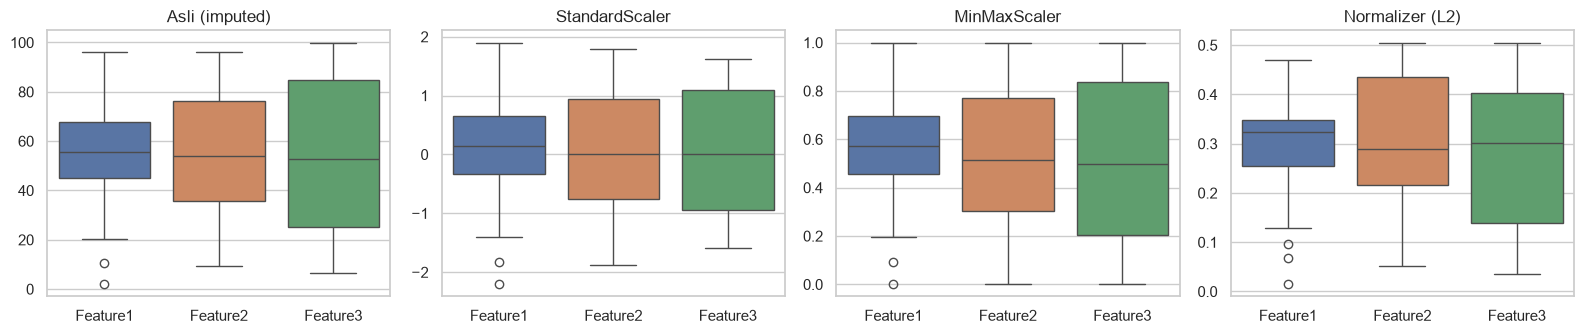

In [13]:
# Tambahan: verifikasi norma L2 setiap baris = 1, dan bandingkan distribusi ketiga hasil scaling
print("Norma L2 lima baris pertama:", np.linalg.norm(normalized_df.values, axis=1)[:5].round(6))

fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=False)
for ax, (judul, d) in zip(
    axes,
    [("Asli (imputed)", iterative_imputed_df), ("StandardScaler", scaled_df),
     ("MinMaxScaler", minmax_scaled_df), ("Normalizer (L2)", normalized_df)],
):
    sns.boxplot(data=d[["Feature1", "Feature2", "Feature3"]], ax=ax)
    ax.set_title(judul)
plt.tight_layout()
plt.show()

**Interpretasi:** Setiap **baris** hasil `Normalizer` memiliki panjang vektor (norma L2) tepat 1, sehingga yang dipertahankan adalah **arah/proporsi** antar-fitur dalam satu sampel, bukan besarnya. Boxplot menunjukkan perbedaan konsep: `StandardScaler` memusatkan kolom di 0, `MinMaxScaler` memampatkan kolom ke $[0,1]$, sedangkan `Normalizer` bekerja per baris sehingga nilai tiap kolom kecil (~0,1–0,5, karena dibagi norma 10 fitur) dan tidak menjamin mean/varians kolom tertentu. Jadi `Normalizer` **bukan** pengganti scaler per-fitur; ia dipakai ketika yang penting adalah kemiripan arah antar-sampel.

## 2.3 Encoding Variabel Kategorikal

**Teori:**

Model matematika hanya memahami angka, sehingga variabel kategorikal (teks/label) harus dienkode. Jenis variabel kategorikal:
- **Nominal** — tidak ada urutan (Department: A, B, C, D; Location: NY, SF, …).
- **Ordinal** — ada urutan alami (Position: Junior < Senior < Manager).

**1. One-Hot Encoding (`OneHotEncoder`)** — variabel dengan $K$ kategori diubah menjadi $K$ kolom biner (*dummy*):
$$\text{onehot}(x) = [\,\mathbb{1}(x=c_1),\ \mathbb{1}(x=c_2),\ \dots,\ \mathbb{1}(x=c_K)\,]$$
Contoh: `Location = "SF"` dengan kategori (CHI, LA, NY, SF) → `[0, 0, 0, 1]`. Kelebihan: tidak memaksakan urutan palsu. Kekurangan: dimensi bertambah ($\sum_j K_j$ kolom) — masalah untuk kardinalitas tinggi. Kolom-kolom one-hot dari satu variabel selalu berjumlah 1, sehingga terjadi multikolinearitas sempurna (*dummy variable trap*) bagi model linear tanpa regularisasi; dapat diatasi dengan `drop="first"`. Parameter penting: `handle_unknown="ignore"` (kategori baru di data uji menjadi vektor nol), `sparse_output` (output matriks sparse/dense; sebelum versi 1.2 bernama `sparse`).

**2. Label Encoding (`LabelEncoder`)** — memetakan setiap kategori ke bilangan bulat $0,\dots,K-1$ (urutan alfabetis):
$$\text{label}(c_k) = k-1$$
Dirancang untuk **variabel target** $y$ (klasifikasi), sehingga hanya menerima input 1-D. Jika dipakai untuk **fitur** nominal, model linear/berbasis jarak akan salah menafsirkan "A < B < C" dan jarak $|0-2| > |0-1|$ yang sebenarnya tidak bermakna. Untuk fitur, padanannya adalah `OrdinalEncoder` (menerima 2-D dan bisa diberi urutan kategori eksplisit). Model berbasis pohon relatif toleran terhadap encoding integer.

| Encoder | Input | Output | Cocok untuk |
|---|---|---|---|
| `OneHotEncoder` | fitur 2-D | $K$ kolom biner per fitur | fitur nominal, kardinalitas rendah–sedang |
| `OrdinalEncoder` | fitur 2-D | 1 kolom integer per fitur | fitur ordinal / model pohon |
| `LabelEncoder` | target 1-D | 1 vektor integer | label kelas $y$ |

**3. `ColumnTransformer`** — data nyata biasanya **campuran** (numerik + kategorikal) dan tiap tipe butuh transformasi berbeda. `ColumnTransformer` menerapkan transformer berbeda pada subset kolom berbeda secara paralel, lalu menggabungkan (*horizontal concatenation*) hasilnya:
$$X' = \big[\ T_1(X_{[:, C_1]})\ \big|\ T_2(X_{[:, C_2]})\ \big|\ \dots\ \big]$$
Kolom yang tidak disebut di-*drop* secara default, atau diteruskan apa adanya dengan `remainder="passthrough"`.

### Getting ready
Dataset kategorikal sintetis dengan 20 baris dan 3 fitur: `Department` (A–D), `Position` (Junior/Senior/Manager), `Location` (NY/SF/LA/CHI).

In [14]:
# Load libraries
import numpy as np

# Membuat data kategorikal sampel dengan 20 record
np.random.seed(2024)  # untuk reproducibility
categories = ["A", "B", "C", "D"]
categorical_data = pd.DataFrame(
    {
        "Department": np.random.choice(categories, size=20),
        "Position": np.random.choice(["Junior", "Senior", "Manager"], size=20),
        "Location": np.random.choice(["NY", "SF", "LA", "CHI"], size=20),
    }
)

# Menampilkan DataFrame berisi nilai kategorikal
display(categorical_data)

,Department,Position,Location
0,A,Manager,LA
1,C,Manager,LA
2,A,Junior,NY
3,A,Manager,LA
4,D,Manager,NY
5,A,Senior,LA
6,C,Manager,SF
7,D,Manager,LA
8,B,Junior,LA
9,D,Manager,CHI


**Interpretasi:** Ketiga kolom bertipe teks (`object`), sehingga belum dapat dipakai langsung oleh estimator. Total ada $4 + 3 + 4 = 11$ kategori unik — inilah jumlah kolom yang akan dihasilkan one-hot encoding.

### How to do it — `OneHotEncoder`

In [15]:
# Load libraries
from sklearn.preprocessing import OneHotEncoder

# Inisialisasi OneHotEncoder dengan output dense (bukan sparse matrix)
onehot_encoder = OneHotEncoder(sparse_output=False)

# Fit dan transform data
onehot_encoded_data = onehot_encoder.fit_transform(categorical_data)
onehot_encoded_df = pd.DataFrame(
    onehot_encoded_data, columns=onehot_encoder.get_feature_names_out()
)
onehot_encoded_df

,Department_A,Department_B,Department_C,Department_D,Position_Junior,Position_Manager,Position_Senior,Location_CHI,Location_LA,Location_NY,Location_SF
0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
1,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
2,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
5,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0
6,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
7,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
8,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0
9,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [16]:
# Tambahan: kategori yang dipelajari dan cek bahwa tiap variabel menyumbang tepat satu angka 1 per baris
print("Kategori per fitur:", [list(c) for c in onehot_encoder.categories_])
print("Shape hasil:", onehot_encoded_df.shape)
print("Jumlah angka 1 per baris (harus = 3):", onehot_encoded_df.sum(axis=1).unique())

Kategori per fitur: [['A', 'B', 'C', 'D'], ['Junior', 'Manager', 'Senior'], ['CHI', 'LA', 'NY', 'SF']]
Shape hasil: (20, 11)
Jumlah angka 1 per baris (harus = 3): [3.]


**Interpretasi:** Tiga kolom kategorikal berubah menjadi 11 kolom biner dengan nama `<fitur>_<kategori>` (misalnya `Location_SF`). Setiap baris memiliki tepat tiga angka 1 — satu untuk setiap variabel asal — dan sisanya 0. Kategori diurutkan secara alfabetis (`categories_`). Representasi ini tidak menyiratkan urutan apa pun antar-kategori.

### How to do it — `LabelEncoder`
Mengikuti buku, `LabelEncoder` diterapkan kolom per kolom (karena hanya menerima input 1-D) untuk memperlihatkan pemetaan integer.

In [17]:
# Load libraries
from sklearn.preprocessing import LabelEncoder

# Inisialisasi LabelEncoder
label_encoder = LabelEncoder()

# DataFrame baru untuk menampung hasil label encoding
label_encoded_df = pd.DataFrame()

# Fit dan transform setiap kolom kategorikal secara terpisah
for column in categorical_data.columns:
    label_encoded_df[f"{column}_encoded"] = label_encoder.fit_transform(
        categorical_data[column]
    )
    # Tambahan: tampilkan pemetaan kategori -> integer
    print(f"{column:<11}:", dict(zip(label_encoder.classes_, range(len(label_encoder.classes_)))))
label_encoded_df

Department : {'A': 0, 'B': 1, 'C': 2, 'D': 3}
Position   : {'Junior': 0, 'Manager': 1, 'Senior': 2}
Location   : {'CHI': 0, 'LA': 1, 'NY': 2, 'SF': 3}


,Department_encoded,Position_encoded,Location_encoded
0,0,1,1
1,2,1,1
2,0,0,2
3,0,1,1
4,3,1,2
5,0,2,1
6,2,1,3
7,3,1,1
8,1,0,1
9,3,1,0


**Interpretasi:** Setiap kategori diganti integer berdasarkan urutan alfabetis. Perhatikan `Position`: `Junior → 0, Manager → 1, Senior → 2` — urutan ini **tidak** sesuai dengan hierarki sebenarnya (Junior < Senior < Manager). Ini menunjukkan risiko memakai `LabelEncoder` untuk fitur: model linear akan menafsirkan Senior "lebih besar" dari Manager. Untuk fitur ordinal sebaiknya memakai `OrdinalEncoder(categories=[["Junior", "Senior", "Manager"]])`; `LabelEncoder` idealnya untuk target $y$. Catatan: karena objek `label_encoder` yang sama di-fit ulang di setiap loop, setelah loop ia hanya "mengingat" kolom terakhir (`Location`).

### How to do it — `ColumnTransformer`
Data campuran: 3 kolom numerik (Age, Salary, Experience) di-standardisasi, 2 kolom kategorikal (Department, Position) di-one-hot.

In [18]:
# Load libraries
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler

# Membuat data campuran (numerik + kategorikal) dengan 20 record
np.random.seed(2024)  # untuk reproducibility
mixed_data = pd.DataFrame(
    {
        "Age": np.random.randint(25, 65, size=20),
        "Salary": np.round(np.random.normal(60000, 15000, size=20), 2),
        "Experience": np.random.randint(1, 20, size=20),
        "Department": np.random.choice(["IT", "HR", "Sales", "Finance"], size=20),
        "Position": np.random.choice(["Junior", "Senior", "Manager"], size=20),
    }
)

# Menampilkan DataFrame data campuran
display(mixed_data)

# Inisialisasi ColumnTransformer: transformer berbeda untuk kelompok kolom berbeda
column_transformer = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), ["Age", "Salary", "Experience"]),
        ("cat", OneHotEncoder(), ["Department", "Position"]),
    ],
    remainder="passthrough",  # kolom lain (jika ada) diteruskan tanpa diubah
)

# Fit dan transform data
transformed_data = column_transformer.fit_transform(mixed_data)

# Nama fitur untuk kolom hasil transformasi
numeric_cols = ["Age_scaled", "Salary_scaled", "Experience_scaled"]
categorical_cols = column_transformer.named_transformers_["cat"].get_feature_names_out(
    ["Department", "Position"]
)

# Membuat DataFrame hasil transformasi
transformed_df = pd.DataFrame(
    transformed_data, columns=numeric_cols + list(categorical_cols)
)
transformed_df

,Age,Salary,Experience,Department,Position
0,33,59420.36,12,Finance,Manager
1,57,82895.92,17,Sales,Junior
2,25,38165.76,16,Finance,Manager
3,52,38242.36,7,IT,Junior
4,61,55088.65,8,Sales,Manager
5,26,78688.88,9,Sales,Senior
6,60,49585.62,14,Finance,Junior
7,35,47992.58,17,HR,Manager
8,27,54833.02,9,Sales,Senior
9,57,93535.56,14,Sales,Senior


,Age_scaled,Salary_scaled,Experience_scaled,Department_Finance,Department_HR,Department_IT,Department_Sales,Position_Junior,Position_Manager,Position_Senior
0,-1.045,-0.305,0.327,1.0,0.0,0.0,0.0,0.0,1.0,0.0
1,0.728,1.105,1.262,0.0,0.0,0.0,1.0,1.0,0.0,0.0
2,-1.636,-1.582,1.075,1.0,0.0,0.0,0.0,0.0,1.0,0.0
3,0.358,-1.577,-0.608,0.0,0.0,1.0,0.0,1.0,0.0,0.0
4,1.023,-0.565,-0.421,0.0,0.0,0.0,1.0,0.0,1.0,0.0
5,-1.562,0.852,-0.234,0.0,0.0,0.0,1.0,0.0,0.0,1.0
6,0.949,-0.896,0.701,1.0,0.0,0.0,0.0,1.0,0.0,0.0
7,-0.898,-0.991,1.262,0.0,1.0,0.0,0.0,0.0,1.0,0.0
8,-1.489,-0.581,-0.234,0.0,0.0,0.0,1.0,0.0,0.0,1.0
9,0.728,1.744,0.701,0.0,0.0,0.0,1.0,0.0,0.0,1.0


In [19]:
# Tambahan: cara modern mendapatkan nama fitur langsung dari ColumnTransformer
print("Tipe output   :", type(transformed_data).__name__, transformed_data.shape)
print("Nama fitur CT :", list(column_transformer.get_feature_names_out()))

Tipe output   : ndarray (20, 10)
Nama fitur CT : ['num__Age', 'num__Salary', 'num__Experience', 'cat__Department_Finance', 'cat__Department_HR', 'cat__Department_IT', 'cat__Department_Sales', 'cat__Position_Junior', 'cat__Position_Manager', 'cat__Position_Senior']


**Interpretasi:** Hasilnya adalah satu matriks berukuran $20 \times 10$: 3 kolom numerik terstandardisasi + 4 kolom `Department_*` + 3 kolom `Position_*`. Walaupun `OneHotEncoder` di sini memakai default `sparse_output=True`, output akhirnya berupa array **dense** karena `ColumnTransformer` hanya mengembalikan sparse matrix jika kepadatan (*density*) keseluruhan di bawah `sparse_threshold=0.3`; di sini 5 dari 10 nilai per baris tidak nol (density 0,5). Metode `get_feature_names_out()` pada `ColumnTransformer` memberi nama dengan prefix transformer (`num__`, `cat__`), alternatif yang lebih praktis daripada menyusun nama kolom secara manual.

## 2.4 Pengantar Pipeline

**Teori:**

`Pipeline` merangkai beberapa langkah menjadi **satu estimator gabungan**: $n-1$ langkah pertama harus berupa *transformer* (punya `fit` dan `transform`), dan langkah terakhir boleh berupa transformer atau estimator (model). Secara matematis, pipeline adalah **komposisi fungsi**:
$$\hat{y} = f\big(T_k(\dots T_2(T_1(X))\dots)\big)$$

Saat `pipeline.fit(X_train, y_train)` dipanggil:
1. $T_1$.`fit_transform(X_train)` → $X^{(1)}$
2. $T_2$.`fit_transform(X^{(1)})` → $X^{(2)}$, … dan seterusnya
3. estimator akhir `fit(X^{(k)}, y_train)`

Saat `pipeline.predict(X_test)` / `transform(X_test)`: hanya `transform` yang dipanggil di setiap langkah, memakai parameter yang dipelajari dari data latih.

**Manfaat utama:**

| Manfaat | Penjelasan |
|---|---|
| Mencegah *data leakage* | Statistik preprocessing (mean, std, kategori) hanya dihitung dari data latih — terutama penting di dalam *cross-validation* |
| Kode ringkas & konsisten | Satu objek, satu `fit`/`predict`; mengurangi kesalahan urutan langkah |
| Tuning bersama | Hyperparameter preprocessing dan model bisa dicari sekaligus dengan `GridSearchCV` (sintaks `nama_langkah__parameter`) |
| Mudah disimpan/di-*deploy* | Seluruh alur dapat disimpan sebagai satu objek (misalnya dengan `joblib`) |

Sintaks umum:
```python
pipeline = Pipeline([
    ("nama_langkah_1", transformer_1),
    ("nama_langkah_2", transformer_2),
    ...,
    ("nama_langkah_akhir", estimator),
])
```
Alternatif singkat: `make_pipeline(t1, t2, est)` yang memberi nama langkah otomatis.

**Train–test split.** Sebelum melatih apa pun, data dibagi menjadi data latih dan data uji (`train_test_split`, di sini 80%/20%) agar evaluasi mengukur kemampuan generalisasi pada data yang belum pernah dilihat.

### How to do it
Mengikuti buku, `transformed_df` dari recipe 2.3 dipakai sebagai data: kolom terakhir (`Position_Senior`) dijadikan target $y$ dan sisanya sebagai fitur $X$ — ini sekadar ilustrasi mekanisme pipeline, bukan masalah prediksi yang bermakna.

In [20]:
# Load libraries
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Pisahkan fitur dan target (kolom terakhir dianggap target)
X = transformed_df.iloc[:, :-1]  # semua kolom kecuali yang terakhir
y = transformed_df.iloc[:, -1]  # kolom terakhir

# Split data menjadi train (80%) dan test (20%)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2024
)

# Membuat pipeline
pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="mean")),  # menangani missing values
        ("scaler", StandardScaler()),  # menskalakan fitur
    ]
)

# Fit dan transform data latih
X_train_transformed = pipeline.fit_transform(X_train)

# Transform data uji (memakai parameter dari data latih)
X_test_transformed = pipeline.transform(X_test)

# Membuat DataFrame dari data hasil transformasi (agar nama kolom tetap ada)
X_train_transformed = pd.DataFrame(
    X_train_transformed, columns=X_train.columns, index=X_train.index
)

X_test_transformed = pd.DataFrame(
    X_test_transformed, columns=X_test.columns, index=X_test.index
)

# Tambahan: ringkasan hasil
print("Target y        :", y.name)
print("X_train / X_test:", X_train_transformed.shape, X_test_transformed.shape)
print("Mean kolom train (≈0):", X_train_transformed.mean().abs().max().round(6))
print("Mean kolom test  (tidak harus 0):")
display(X_test_transformed.mean().round(3).to_frame("mean_test").T)

Target y        : Position_Senior
X_train / X_test: (16, 9) (4, 9)
Mean kolom train (≈0): 0.0
Mean kolom test  (tidak harus 0):


,Age_scaled,Salary_scaled,Experience_scaled,Department_Finance,Department_HR,Department_IT,Department_Sales,Position_Junior,Position_Manager
mean_test,0.961,0.078,0.503,0.577,0.16,0.16,-0.775,1.732,-1.0


**Interpretasi:** Dari 20 baris, 16 menjadi data latih dan 4 data uji; fitur berjumlah 9 kolom (10 kolom dikurangi target `Position_Senior`). Pada data latih, rata-rata setiap kolom hasil pipeline ≈ 0 karena scaler di-*fit* di sana. Pada data uji, rata-ratanya **tidak** nol — itu justru benar, sebab data uji ditransformasi memakai $\mu$ dan $\sigma$ data latih (tidak ada kebocoran informasi). Langkah `SimpleImputer` tidak mengubah apa pun di sini karena data tidak memiliki `NaN`, namun tetap berguna sebagai pengaman bila data baru mengandung nilai hilang.

### Visualizing Pipelines

**Teori:** Dengan `set_config(display="diagram")`, objek estimator/pipeline di Jupyter ditampilkan sebagai diagram HTML interaktif: setiap langkah berupa kotak yang bisa diklik untuk melihat parameternya. Sejak scikit-learn 1.0-an, `"diagram"` sudah menjadi default, sehingga baris ini lebih bersifat eksplisit. Diagram sangat membantu memeriksa pipeline kompleks (misalnya `ColumnTransformer` bersarang di dalam `Pipeline`).

In [21]:
# Load libraries
from sklearn import set_config

# Mengatur konfigurasi tampilan menjadi diagram
set_config(display="diagram")

# Menampilkan pipeline
pipeline

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](9,)","['Age_scaled','Salary_scaled','Experience_scaled',...,'Department_Sales', 'Position_Junior','Position_Manager']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,9
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'mean'
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" f

**Interpretasi:** Diagram menampilkan dua langkah berurutan — `imputer` (`SimpleImputer`) lalu `scaler` (`StandardScaler`) — sesuai urutan eksekusi data. Status "fitted" juga ditandai karena pipeline sudah di-`fit`. Jika notebook dibuka di viewer yang tidak menjalankan HTML (misalnya GitHub), yang tampil adalah representasi teks dari pipeline.

## 2.5 Feature Engineering

**Teori:**

*Feature engineering* adalah proses membuat fitur baru atau mengubah fitur lama agar pola dalam data lebih mudah ditangkap model. *Feature selection* adalah proses memilih subset fitur yang paling relevan — mengurangi overfitting, waktu komputasi, dan meningkatkan interpretabilitas.

**1. `PolynomialFeatures` (ekspansi polinomial & interaksi).** Untuk $p$ fitur dan derajat $d$, dibuat semua monomial dengan total derajat $\le d$. Untuk $d=2$ dan dua fitur $x_1, x_2$:
$$[x_1, x_2] \;\longrightarrow\; [1,\ x_1,\ x_2,\ x_1^2,\ x_1x_2,\ x_2^2]$$
Jumlah fitur output (termasuk bias): $\binom{p+d}{d}$. Untuk $p=9, d=2$: $\binom{11}{2} = 55$. Ini memungkinkan model **linear** menangkap hubungan **non-linear** dan interaksi antar-fitur, karena model tetap linear terhadap parameter: $\hat{y} = \beta_0 + \sum_j \beta_j x_j + \sum_{j\le k}\beta_{jk}x_jx_k$. Risikonya: ledakan dimensi dan overfitting (sering dipadukan dengan regularisasi). Opsi `interaction_only=True` hanya membuat suku interaksi; `include_bias=False` menghilangkan kolom konstanta 1.

**2. `KBinsDiscretizer` (diskretisasi/binning).** Mengubah fitur kontinu menjadi $k$ interval (bin). Strategi:

| `strategy` | Batas bin | Karakteristik |
|---|---|---|
| `uniform` | lebar sama: $b_m = \min + m\cdot\frac{\max-\min}{k}$ | sederhana; bin bisa kosong bila data miring |
| `quantile` | kuantil: setiap bin berisi ≈ jumlah sampel sama | tahan outlier |
| `kmeans` | batas di tengah antar-centroid k-Means 1-D | mengikuti kelompok alami data |

Output `encode="ordinal"` berupa indeks bin $0,\dots,k-1$; `encode="onehot"` berupa matriks biner. Binning dapat membantu model linear menangkap pola non-linear (fungsi tangga) dan mengurangi pengaruh noise/outlier, dengan konsekuensi hilangnya sebagian informasi.

**3. `RFE` — Recursive Feature Elimination (metode *wrapper*).** Algoritma:
1. Latih estimator pada semua fitur yang tersisa.
2. Hitung skor kepentingan tiap fitur (dari `coef_` atau `feature_importances_`; untuk model linear dipakai $|\beta_j|$).
3. Buang fitur dengan skor terkecil (sebanyak `step`).
4. Ulangi sampai tersisa `n_features_to_select` fitur.

Atribut `ranking_` memberi peringkat: 1 = terpilih, angka lebih besar = dibuang lebih awal. Perhatikan: $|\beta_j|$ hanya sebanding antar-fitur jika fitur memiliki skala yang sama — itulah mengapa data distandardisasi terlebih dahulu.

**4. `SelectFromModel` (metode *embedded*).** Melatih estimator **sekali**, lalu mempertahankan fitur yang skor kepentingannya ≥ ambang (`threshold`):
$$\text{pilih fitur } j \iff |\beta_j| \ge \tau, \qquad \tau = \text{mean}(|\beta_1|,\dots,|\beta_p|) \ \text{bila threshold="mean"}$$
Ambang lain: `"median"`, kelipatan seperti `"1.25*mean"`, atau angka. Lebih cepat dari RFE karena tidak iteratif, tetapi tidak mempertimbangkan perubahan kepentingan setelah fitur lain dibuang.

| Metode | Kelompok | Biaya komputasi | Mempertimbangkan interaksi antar-fitur? |
|---|---|---|---|
| Filter (mis. `SelectKBest`) | statistik univariat | rendah | tidak |
| `SelectFromModel` | embedded | sedang (1× fit) | sebagian (via model) |
| `RFE` | wrapper | tinggi (banyak fit) | ya, secara iteratif |

### Getting ready
Recipe ini memakai `X_train_transformed` (16 baris × 9 fitur terstandardisasi) dari recipe 2.4.

### How to do it — `PolynomialFeatures`

In [22]:
# Load libraries
from sklearn.preprocessing import PolynomialFeatures

# Inisialisasi PolynomialFeatures derajat 2
poly = PolynomialFeatures(degree=2)

# Fit dan transform data X_train_transformed
poly_features = poly.fit_transform(X_train_transformed)
poly_features_df = pd.DataFrame(
    poly_features, columns=poly.get_feature_names_out(X_train_transformed.columns)
)
print("Jumlah fitur: input =", poly.n_features_in_, "-> output =", poly.n_output_features_)
poly_features_df

Jumlah fitur: input = 9 -> output = 55


,1,Age_scaled,Salary_scaled,Experience_scaled,Department_Finance,Department_HR,Department_IT,Department_Sales,Position_Junior,Position_Manager,Age_scaled^2,Age_scaled Salary_scaled,Age_scaled Experience_scaled,Age_scaled Department_Finance,Age_scaled Department_HR,Age_scaled Department_IT,Age_scaled Department_Sales,Age_scaled Position_Junior,Age_scaled Position_Manager,Salary_scaled^2,Salary_scaled Experience_scaled,Salary_scaled Department_Finance,Salary_scaled Department_HR,Salary_scaled Department_IT,Salary_scaled Department_Sales,...,Experience_scaled Department_IT,Experience_scaled Department_Sales,Experience_scaled Position_Junior,Experience_scaled Position_Manager,Department_Finance^2,Department_Finance Department_HR,Department_Finance Department_IT,Department_Finance Department_Sales,Department_Finance Position_Junior,Department_Finance Position_Manager,Department_HR^2,Department_HR Department_IT,Department_HR Department_Sales,Department_HR Position_Junior,Department_HR Position_Manager,Department_IT^2,Department_IT Department_Sales,Department_IT Position_Junior,Department_IT Position_Manager,Department_Sales^2,Department_Sales Position_Junior,Department_Sales Position_Manager,Position_Junior^2,Position_Junior Position_Manager,Position_Manager^2
0,1.0,0.834,-0.867,-1.560,-0.577,-0.480,2.082,-0.775,-0.577,-1.0,0.696,-0.724,-1.301,-0.482,-0.401,1.737,-0.646,-0.482,-0.834,0.752,1.353,0.501,0.417,-1.806,0.672,...,-3.247,1.208,0.901,1.560,0.333,0.277,-1.202,0.447,0.333,0.577,0.231,-1.000,0.372,0.277,0.480,4.333,-1.612,-1.202,-2.082,0.600,0.447,0.775,0.333,0.577,1.0
1,1.0,-0.689,1.283,-0.151,-0.577,2.082,-0.480,-0.775,-0.577,1.0,0.475,-0.884,0.104,0.398,-1.435,0.331,0.534,0.398,-0.689,1.646,-0.194,-0.741,2.670,-0.616,-0.994,...,0.073,0.117,0.087,-0.151,0.333,-1.202,0.277,0.447,0.333,-0.577,4.333,-1.000,-1.612,-1.202,2.082,0.231,0.372,0.277,-0.480,0.600,0.447,-0.775,0.333,-0.577,1.0
2,1.0,0.544,-1.173,-1.761,-0.577,-0.480,2.082,-0.775,-0.577,1.0,0.296,-0.638,-0.958,-0.314,-0.261,1.133,-0.421,-0.314,0.544,1.377,2.066,0.677,0.564,-2.443,0.909,...,-3.666,1.364,1.017,-1.761,0.333,0.277,-1.202,0.447,0.333,-0.577,0.231,-1.000,0.372,0.277,-0.480,4.333,-1.612,-1.202,2.082,0.600,0.447,-0.775,0.333,-0.577,1.0
3,1.0,-1.342,0.822,-0.151,-0.577,-0.480,-0.480,1.291,-0.577,-1.0,1.801,-1.103,0.203,0.775,0.645,0.645,-1.733,0.775,1.342,0.675,-0.124,-0.474,-0.395,-0.395,1.061,...,0.073,-0.195,0.087,0.151,0.333,0.277,0.277,-0.745,0.333,0.577,0.231,0.231,-0.620,0.277,0.480,0.231,-0.620,0.277,0.480,1.667,-0.745,-1.291,0.333,0.577,1.0
4,1.0,1.415,0.611,0.654,-0.577,-0.480,-0.480,1.291,-0.577,1.0,2.001,0.865,0.925,-0.817,-0.680,-0.680,1.826,-0.817,1.415,0.373,0.400,-0.353,-0.294,-0.294,0.789,...,-0.314,0.844,-0.378,0.654,0.333,0.277,0.277,-0.745,0.333,-0.577,0.231,0.231,-0.620,0.277,-0.480,0.231,-0.620,0.277,-0.480,1.667,-0.745,1.291,0.333,-0.577,1.0
5,1.0,-1.415,-1.480,1.258,1.732,-0.480,-0.480,-0.775,-0.577,1.0,2.001,2.093,-1.780,-2.450,0.680,0.680,1.096,0.817,-1.415,2.190,-1.861,-2.563,0.711,0.711,1.146,...,-0.604,-0.974,-0.726,1.258,3.000,-0.832,-0.832,-1.342,-1.000,1.732,0.231,0.231,0.372,0.277,-0.480,0.231,0.372,0.277,-0.480,0.600,0.447,-0.775,0.333,-0.577,1.0
6,1.0,1.270,0.577,0.453,1.732,-0.480,-0.480,-0.775,1.732,-1.0,1.612,0.732,0.575,2.199,-0.610,-0.610,-0.983,2.199,-1.270,0.333,0.261,0.999,-0.277,-0.277,-0.447,...,-0.218,-0.351,0.784,-0.453,3.000,-0.832,-0.832,-1.342,3.000,-1.732,0.231,0.231,0.372,-0.832,0.480,0.231,0.372,-0.832,0.480,0.600,-1.342,0.775,3.000,-1.732,1.0
7,1.0,0.544,-1.475,-0.553,-0.577,-0.480,2.082,-0.775,1.732,-1.0,0.296,-0.803,-0.301,-0.314,-0.261,1.133,-0.421,0.942,-0.544,2.177,0.817,0.852,0.709,-3.071,1.143,...,-1.152,0.429,-0.959,0.553,0.333,0.277,-1.202,0.447,-1.000,0.577,0.231,-1.000,0.372,-0.832,0.480,4.333,-1.612,3.606,-2.082,0.600,-1.342,0.775,3.000,-1.732,1.0
8,1.0,0.907,1.060,1.459,-0.577,-0.480,-0.480,1.291,1.732,-1.0,0.822,0.962,1.323,-0.524,-0.436,-0.436,1.171,1.571,-0.907,1.125,1.547,-0.612,-0.509,-0.509

**Interpretasi:** Sembilan fitur berkembang menjadi 55 kolom, sesuai rumus $\binom{9+2}{2}=55$: 1 kolom bias (`1`), 9 fitur asli, 9 kuadrat (misalnya `Age_scaled^2`), dan $\binom{9}{2}=36$ suku interaksi (misalnya `Age_scaled Salary_scaled`). Dengan hanya 16 baris data latih, 55 fitur jelas melebihi jumlah sampel — contoh nyata bagaimana ekspansi polinomial bisa memicu overfitting jika tidak disertai regularisasi atau seleksi fitur. Perhatikan juga bahwa kolom dummy yang sudah distandardisasi tidak lagi bernilai 0/1 (misalnya −0,577 dan 1,732), sehingga suku kuadrat dan interaksinya pun ikut berubah skala.

### How to do it — `KBinsDiscretizer`

In [23]:
# Load libraries
from sklearn.preprocessing import KBinsDiscretizer

# Inisialisasi KBinsDiscretizer: 3 bin berlebar sama, output berupa indeks bin
kbins = KBinsDiscretizer(n_bins=3, encode="ordinal", strategy="uniform")

# Fit dan transform data X_train_transformed
binned_data = kbins.fit_transform(X_train_transformed)
binned_df = pd.DataFrame(binned_data, columns=X_train_transformed.columns)
binned_df

,Age_scaled,Salary_scaled,Experience_scaled,Department_Finance,Department_HR,Department_IT,Department_Sales,Position_Junior,Position_Manager
0,2.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0
1,0.0,2.0,1.0,0.0,2.0,0.0,0.0,0.0,2.0
2,2.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,2.0
3,0.0,2.0,1.0,0.0,0.0,0.0,2.0,0.0,0.0
4,2.0,1.0,2.0,0.0,0.0,0.0,2.0,0.0,2.0
5,0.0,0.0,2.0,2.0,0.0,0.0,0.0,0.0,2.0
6,2.0,1.0,2.0,2.0,0.0,0.0,0.0,2.0,0.0
7,2.0,0.0,1.0,0.0,0.0,2.0,0.0,2.0,0.0
8,2.0,2.0,2.0,0.0,0.0,0.0,2.0,2.0,0.0
9,2.0,2.0,2.0,0.0,0.0,0.0,2.0,0.0,0.0


In [24]:
# Tambahan: batas-batas bin yang dipelajari untuk fitur numerik, dan jumlah sampel per bin
for nama, edges in zip(X_train_transformed.columns[:3], kbins.bin_edges_[:3]):
    print(f"{nama:<18} batas bin: {np.round(edges, 3)}")
binned_df.iloc[:, :3].apply(pd.Series.value_counts).fillna(0).astype(int)

Age_scaled         batas bin: [-1.415 -0.472  0.472  1.415]
Salary_scaled      batas bin: [-1.48  -0.432  0.617  1.665]
Experience_scaled  batas bin: [-1.761 -0.688  0.386  1.459]


,Age_scaled,Salary_scaled,Experience_scaled
0.0,8,7,3
1.0,0,4,6
2.0,8,5,7


**Interpretasi:** Setiap nilai kontinu diganti dengan indeks bin 0, 1, atau 2. Untuk fitur numerik seperti `Age_scaled`, rentang $[\min, \max]$ dibagi menjadi tiga interval berlebar sama (lihat `bin_edges_`), dan jumlah sampel per bin tidak harus seimbang karena strategi `uniform` mengikuti lebar, bukan frekuensi. Untuk kolom dummy hasil one-hot (yang hanya memiliki dua nilai unik setelah standardisasi), binning hanya menghasilkan bin terendah dan tertinggi — diskretisasi pada fitur biner tidak menambah informasi, sehingga dalam praktik `KBinsDiscretizer` sebaiknya hanya diterapkan pada fitur kontinu (misalnya lewat `ColumnTransformer`).

### How to do it — `RFE`

In [25]:
# Load libraries
from sklearn.feature_selection import RFE
from sklearn.linear_model import LinearRegression

# Inisialisasi RFE: eliminasi fitur satu per satu hingga tersisa 1 fitur
rfe = RFE(estimator=LinearRegression(), n_features_to_select=1)

# Fit RFE pada X_train_transformed dan y_train
rfe.fit(X_train_transformed, y_train)

# Peringkat fitur (1 = paling penting / terakhir bertahan)
rfe.ranking_

array([7, 5, 4, 3, 6, 9, 8, 2, 1])

In [26]:
# Tambahan: peringkat dalam bentuk tabel yang mudah dibaca
pd.DataFrame({"Feature": X_train_transformed.columns, "Ranking": rfe.ranking_}).sort_values("Ranking")

,Feature,Ranking
8,Position_Manager,1
7,Position_Junior,2
3,Department_Finance,3
2,Experience_scaled,4
1,Salary_scaled,5
4,Department_HR,6
0,Age_scaled,7
6,Department_Sales,8
5,Department_IT,9


**Interpretasi:** Karena `n_features_to_select=1`, RFE terus membuang fitur sampai hanya satu yang tersisa; array `ranking_` menunjukkan urutan eliminasi — ranking 1 bertahan paling akhir, ranking 9 dibuang paling awal. Hasilnya `Position_Manager` (ranking 1) dan `Position_Junior` (ranking 2) menjadi dua fitur terpenting. Ini sangat masuk akal: target `Position_Senior` secara definisi sama dengan $1 - \text{Junior} - \text{Manager}$ (pada skala aslinya), sehingga kedua dummy tersebut menjelaskan target secara **sempurna**, sementara fitur lain sebenarnya tidak relevan. Peringkat 3–9 praktis hanya mencerminkan koefisien berukuran *noise* numerik, sehingga urutannya tidak bermakna. Ini juga contoh *target leakage*: fitur yang merupakan turunan langsung dari target.

### How to do it — `SelectFromModel`

In [27]:
# Load libraries
from sklearn.feature_selection import SelectFromModel
from sklearn.linear_model import LinearRegression

# Inisialisasi SelectFromModel dengan LinearRegression
selector = SelectFromModel(
    estimator=LinearRegression(),
    prefit=False,
    threshold="mean",  # ambang = rata-rata |koefisien|
)

# Fit selector
selector.fit(X_train_transformed, y_train)

# Mask fitur yang terpilih
selected_features_mask = selector.get_support()

# Nama fitur yang terpilih
selected_features = X_train_transformed.columns[selected_features_mask].tolist()

# Skor kepentingan (koefisien) dan status seleksi tiap fitur
feature_importance = pd.DataFrame(
    {
        "Feature": X_train_transformed.columns,
        "Importance": selector.estimator_.coef_,
        "Selected": selected_features_mask,
    }
)
print("Threshold (mean |coef|):", round(float(selector.threshold_), 4))
print("Fitur terpilih:", selected_features)
feature_importance.sort_values("Importance", key=abs, ascending=False)

Threshold (mean |coef|): 0.1037
Fitur terpilih: ['Position_Junior', 'Position_Manager']


,Feature,Importance,Selected
8,Position_Manager,-5.000e-01,True
7,Position_Junior,-4.330e-01,True
2,Experience_scaled,-1.103e-15,False
1,Salary_scaled,1.055e-15,False
4,Department_HR,-4.649e-16,False
3,Department_Finance,4.614e-16,False
6,Department_Sales,-2.810e-16,False
0,Age_scaled,2.078e-16,False
5,Department_IT,-2.047e-16,False


**Interpretasi:** `SelectFromModel` melatih regresi linear sekali, lalu memilih fitur yang $|\beta_j|$-nya ≥ rata-rata nilai absolut semua koefisien (`threshold_` ≈ 0,104). Hanya `Position_Manager` dan `Position_Junior` yang terpilih — keduanya berkoefisien negatif besar (semakin "Junior" atau "Manager", semakin kecil kemungkinan "Senior"), sedangkan koefisien fitur lain berorde $10^{-15}$–$10^{-16}$, yaitu nol secara numerik. Hasil ini konsisten dengan dua peringkat teratas RFE. Secara umum kedua metode tidak harus identik, karena RFE melatih ulang model setiap kali satu fitur dibuang sedangkan `SelectFromModel` hanya sekali fit.

## Latihan — Practical Exercise on Data Preprocessing

**Teori:**

Latihan ini menggabungkan konsep chapter ke dalam satu **pipeline komprehensif** pada dataset **California Housing** (20.640 blok sensus, 8 fitur numerik seperti `MedInc`, `HouseAge`, `AveRooms`, `Latitude`; target = median nilai rumah dalam satuan \$100.000). Pipeline terdiri dari:
1. `SimpleImputer(strategy="median")` — pengaman bila ada nilai hilang (dataset ini sebenarnya lengkap);
2. `StandardScaler()` — standardisasi fitur;
3. `RandomForestRegressor()` — model *ensemble* berupa banyak decision tree yang dilatih pada sampel *bootstrap* dan subset fitur acak, prediksinya dirata-rata: $\hat{y}(\mathbf{x}) = \frac{1}{B}\sum_{b=1}^{B} T_b(\mathbf{x})$.

(Tidak ada langkah encoding karena semua fitur California Housing numerik.)

Evaluasi memakai `pipeline.score()`, yang untuk regressor mengembalikan **koefisien determinasi** $R^2$:
$$R^2 = 1 - \frac{\sum_i (y_i - \hat{y}_i)^2}{\sum_i (y_i - \bar{y})^2}$$
$R^2 = 1$ berarti prediksi sempurna; $R^2 = 0$ setara dengan selalu menebak rata-rata.

> **Catatan adaptasi:** `random_state=2024` dan `n_jobs=-1` ditambahkan pada `RandomForestRegressor` agar hasil reproducible dan pelatihan lebih cepat. Dataset diunduh via `fetch_california_housing()` (perlu internet saat pertama kali, lalu di-cache).

In [28]:
# Load libraries
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

# Memuat dataset California Housing
california_data = fetch_california_housing()
X, y = california_data.data, california_data.target
print("Shape X:", X.shape, "| fitur:", california_data.feature_names)

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=2024
)

# Membuat pipeline komprehensif
comprehensive_pipeline = Pipeline(
    [
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("model", RandomForestRegressor(random_state=2024, n_jobs=-1)),
    ]
)

# Fit pipeline
comprehensive_pipeline.fit(X_train, y_train)

# Evaluasi pipeline (R^2 pada data uji)
score = comprehensive_pipeline.score(X_test, y_test)
score

Shape X: (20640, 8) | fitur: ['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


0.803872822413537

R^2  : 0.8039
MAE  : 0.3318  (x $100.000)
RMSE : 0.5180  (x $100.000)


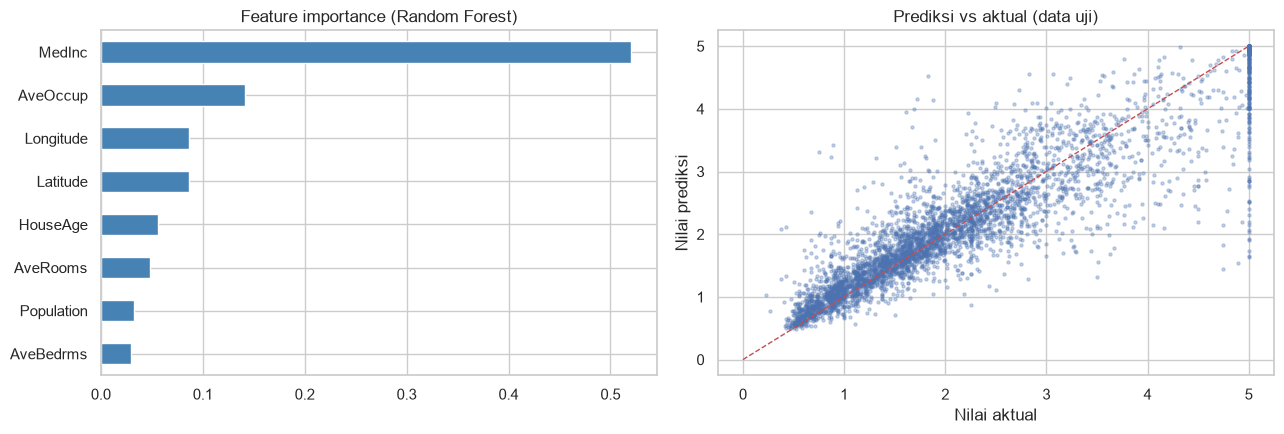

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('imputer', ...), ('scaler', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,8
,"strategy strategy: str or Callable, default='mean'The imputation strategy.- If ""mean"", then replace missing values using the mean along each column. Can only be used with numeric data.- If ""median"", then replace missing values using the median along each column. Can only be used with numeric data.- If ""most_frequent"", then replace missing using the most frequent value along each column. Can be used with strings or numeric data. If there is more than one such value, only the smallest is returned.- If ""constant"", then replace missing values with fill_value. Can be used with strings or numeric data.- If an instance of Callable, then replace missing values using the scalar statistic returned by running the callable over a dense 1d array containing non-missing values of each column... versionadded:: 0.20 strategy=""constant"" for fixed value imputation... versionadded:: 1.5 strategy=callable for custom value imputation.",'median'
,"missing_values missing_values: int, float, str, np.nan, None or pandas.NA, default=np.nanThe placeholder for the missing values. All occurrences of`missing_values` will be imputed. For pandas' dataframes withnullable integer dtypes with missing values, `missing_values`can be set to either `np.nan` or `pd.NA`.",nan
,"fill_value fill_value: str or numerical value, default=NoneWhen strategy == ""constant"", `fill_value` is used to replace alloccurrences of missing_values. For string or object data types,`fill_value` must be a string.If `None`, `fill_value` will be 0 when imputing numericaldata and ""missing_value"" for strings or object data types.",None
,"copy copy: bool, default=TrueIf True, a copy of X will be created. If False, imputation willbe done in-place whenever possible. Note that, in the following cases,a new copy will always be made, even if `copy=False`:- If `X` is not an array of floating values;- If `X` is encoded as a CSR matrix;- If `ad

In [29]:
# Tambahan: metrik error, feature importance, dan plot prediksi vs aktual
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

y_pred = comprehensive_pipeline.predict(X_test)
print(f"R^2  : {score:.4f}")
print(f"MAE  : {mean_absolute_error(y_test, y_pred):.4f}  (x $100.000)")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred):.4f}  (x $100.000)")

importances = pd.Series(
    comprehensive_pipeline.named_steps["model"].feature_importances_,
    index=california_data.feature_names,
).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
importances.plot.barh(ax=axes[0], color="steelblue")
axes[0].set_title("Feature importance (Random Forest)")
axes[1].scatter(y_test, y_pred, s=5, alpha=0.3)
axes[1].plot([0, 5], [0, 5], "r--", lw=1)
axes[1].set_xlabel("Nilai aktual")
axes[1].set_ylabel("Nilai prediksi")
axes[1].set_title("Prediksi vs aktual (data uji)")
plt.tight_layout()
plt.show()

comprehensive_pipeline

**Interpretasi:** Pipeline mencapai $R^2 \approx 0{,}8$ pada data uji, artinya sekitar 80% variasi harga rumah dapat dijelaskan oleh model — jauh lebih baik daripada sekadar menebak rata-rata. `MedInc` (median pendapatan) menjadi fitur paling penting (~52% importance), diikuti `AveOccup` (rata-rata penghuni per rumah) dan informasi lokasi (`Longitude`, `Latitude`). MAE ≈ 0,33 berarti rata-rata kesalahan prediksi sekitar \$33.000. Pada plot prediksi vs aktual, titik-titik mengumpul di sekitar garis diagonal, dengan deviasi terbesar di nilai tinggi; garis vertikal di nilai 5 terjadi karena target dataset ini dipotong (*capped*) di \$500.000. Perlu dicatat bahwa `StandardScaler` sebenarnya tidak berpengaruh pada Random Forest (pohon invarian terhadap skala), tetapi tetap berguna bila model akhir ditukar dengan model yang sensitif skala — salah satu keunggulan desain berbasis pipeline.

## Ringkasan Chapter 2

**Inti materi:**
- **Missing data** — pahami mekanismenya (MCAR/MAR/MNAR) sebelum memilih strategi. `SimpleImputer` (mean/median/modus/konstanta) cepat namun menyusutkan varians; `KNNImputer` memakai tetangga terdekat dengan jarak `nan_euclidean`; `IterativeImputer` (gaya MICE, eksperimental) memodelkan tiap fitur dari fitur lain secara iteratif.
- **Scaling** — `StandardScaler` ($z=(x-\mu)/\sigma$) dan `MinMaxScaler` (ke $[0,1]$) bekerja **per kolom**; `Normalizer` bekerja **per baris** (norma unit, berguna untuk cosine similarity). Model berbasis jarak, gradien, dan regularisasi butuh scaling; model pohon tidak.
- **Encoding** — `OneHotEncoder` untuk fitur nominal (tanpa urutan palsu, tetapi menambah dimensi), `LabelEncoder` untuk target (bukan fitur — gunakan `OrdinalEncoder` untuk fitur ordinal), dan `ColumnTransformer` untuk menerapkan transformasi berbeda pada kolom numerik dan kategorikal sekaligus.
- **Pipeline** — merangkai transformer + estimator sebagai komposisi fungsi; `fit` hanya pada data latih, `transform`/`predict` pada data uji, sehingga mencegah *data leakage* dan memudahkan tuning serta deployment. Diagram pipeline dapat ditampilkan dengan `set_config(display="diagram")`.
- **Feature engineering & selection** — `PolynomialFeatures` menambah suku kuadrat & interaksi ($\binom{p+d}{d}$ fitur); `KBinsDiscretizer` mengubah fitur kontinu menjadi bin (uniform/quantile/kmeans); `RFE` (wrapper, iteratif) dan `SelectFromModel` (embedded, satu kali fit dengan threshold) memilih fitur berdasarkan kepentingan model.
- **Latihan** — pipeline imputer → scaler → Random Forest pada California Housing menghasilkan $R^2 \approx 0{,}8$, dengan `MedInc` sebagai fitur paling berpengaruh.

**Key takeaways:**
1. Semua preprocessing di scikit-learn mengikuti pola **`fit` (belajar parameter dari data latih) → `transform` (terapkan ke data mana pun)**.
2. Jangan pernah melakukan `fit` preprocessing pada keseluruhan data sebelum split — bungkus semua langkah dalam `Pipeline`/`ColumnTransformer`.
3. Pilih teknik sesuai karakter data dan model: outlier → median/`RobustScaler`; fitur nominal → one-hot; model linear + pola non-linear → polynomial/binning; dimensi tinggi → seleksi fitur.
4. Bandingkan hasil sebelum/sesudah transformasi (statistik, visualisasi) untuk memastikan setiap langkah melakukan apa yang dimaksud.
5. Penyesuaian untuk scikit-learn 1.9: `OneHotEncoder(sparse_output=...)` (bukan `sparse`), `IterativeImputer` masih memerlukan `enable_iterative_imputer`, dan `get_feature_names_out()` merupakan cara standar mendapatkan nama fitur hasil transformasi.